In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv("Diabetes_Prediction_Dataset.csv")

## INFO ABOUT DATASET

In [5]:
df.head()

,Patient_ID,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History,Diabetes
0,1,58,Male,17.6,140.0,121,177,86,9.7,Current,High,Yes,Yes
1,2,56,Male,31.0,209.0,143,176,244,8.6,Never,Low,No,Yes
2,3,23,Female,19.4,158.0,167,187,37,9.6,Current,Low,No,No
3,4,41,Male,34.6,81.0,174,178,163,11.4,Never,Low,No,No
4,5,31,Female,34.5,88.0,167,282,102,8.2,Never,Low,No,No


In [6]:
df.shape

(5000, 13)

In [7]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'BMI', 'Glucose', 'Blood_Pressure',
       'Cholesterol', 'Insulin', 'HbA1c', 'Smoking_Status',
       'Physical_Activity', 'Family_History', 'Diabetes'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         5000 non-null   int64  
 1   Age                5000 non-null   int64  
 2   Gender             5000 non-null   str    
 3   BMI                4893 non-null   float64
 4   Glucose            4930 non-null   float64
 5   Blood_Pressure     5000 non-null   int64  
 6   Cholesterol        5000 non-null   int64  
 7   Insulin            5000 non-null   int64  
 8   HbA1c              5000 non-null   float64
 9   Smoking_Status     5000 non-null   str    
 10  Physical_Activity  5000 non-null   str    
 11  Family_History     5000 non-null   str    
 12  Diabetes           5000 non-null   str    
dtypes: float64(3), int64(5), str(5)
memory usage: 611.4 KB


## 2. MISSING VALUE

In [36]:
df.isnull().sum()

Patient_ID             0
Age                    0
Gender                 0
BMI                  107
Glucose               70
Blood_Pressure         0
Cholesterol            0
Insulin                0
HbA1c                  0
Smoking_Status         0
Physical_Activity      0
Family_History         0
Diabetes               0
dtype: int64

In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df.describe()

,Patient_ID,Age,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c
count,5000.000000,5000.000000,4893.000000,4930.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,48.986400,29.407398,144.456795,143.139200,221.426800,157.746200,7.988300
std,1443.520003,18.173813,7.254359,43.887777,87.414816,57.436379,82.357275,2.017408
min,1.000000,18.000000,17.000000,70.000000,90.000000,120.000000,15.000000,4.500000
25%,1250.750000,33.000000,23.100000,106.000000,112.000000,172.000000,86.000000,6.200000
50%,2500.500000,49.000000,29.400000,144.000000,136.000000,222.000000,158.000000,7.900000
75%,3750.250000,65.000000,35.800000,182.000000,158.000000,271.000000,229.000000,9.800000
max,5000.000000,80.000000,42.000000,220.000000,999.000000,320.000000,300.000000,11.500000


In [39]:
df['Diabetes'].value_counts()

Diabetes
Yes    2988
No     2012
Name: count, dtype: int64

In [40]:
df['Diabetes'].value_counts(normalize=True) * 100

Diabetes
Yes    59.76
No     40.24
Name: proportion, dtype: float64

## DATA VISUALISATION

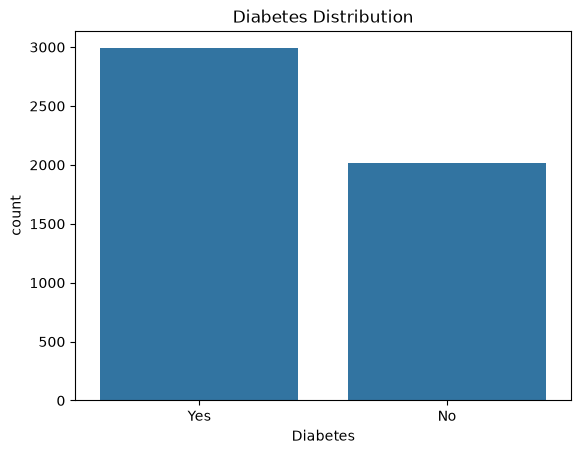

In [16]:
sns.countplot(x='Diabetes', data=df)
plt.title('Diabetes Distribution')
plt.show()

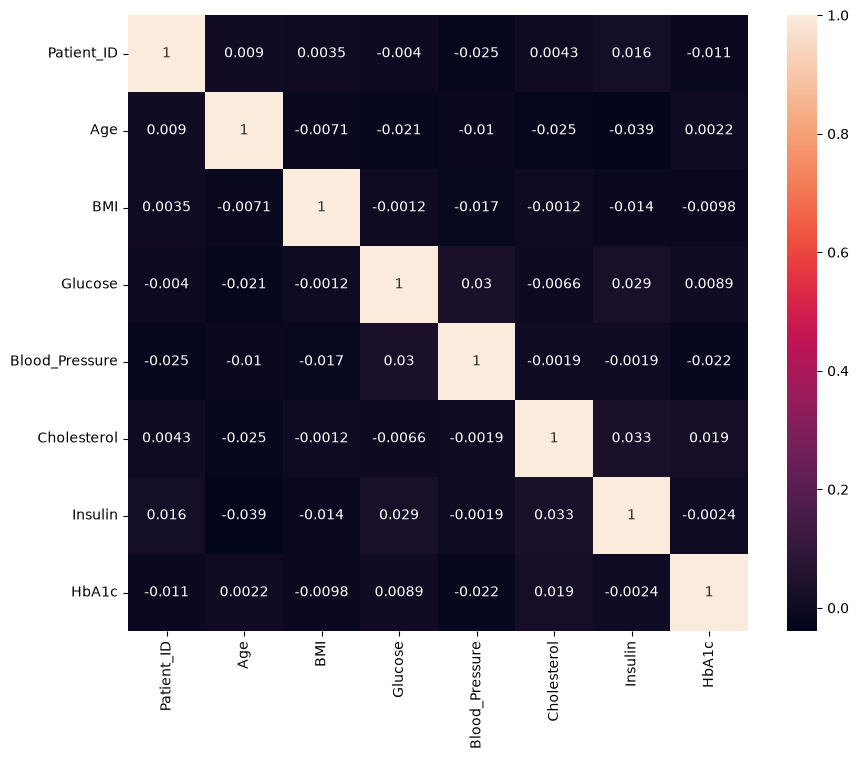

In [17]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

## NUMERICAL COLUMN

In [41]:
num_cols = df.select_dtypes(include=np.number).columns
num_cols

Index(['Patient_ID', 'Age', 'BMI', 'Glucose', 'Blood_Pressure', 'Cholesterol',
       'Insulin', 'HbA1c'],
      dtype='str')

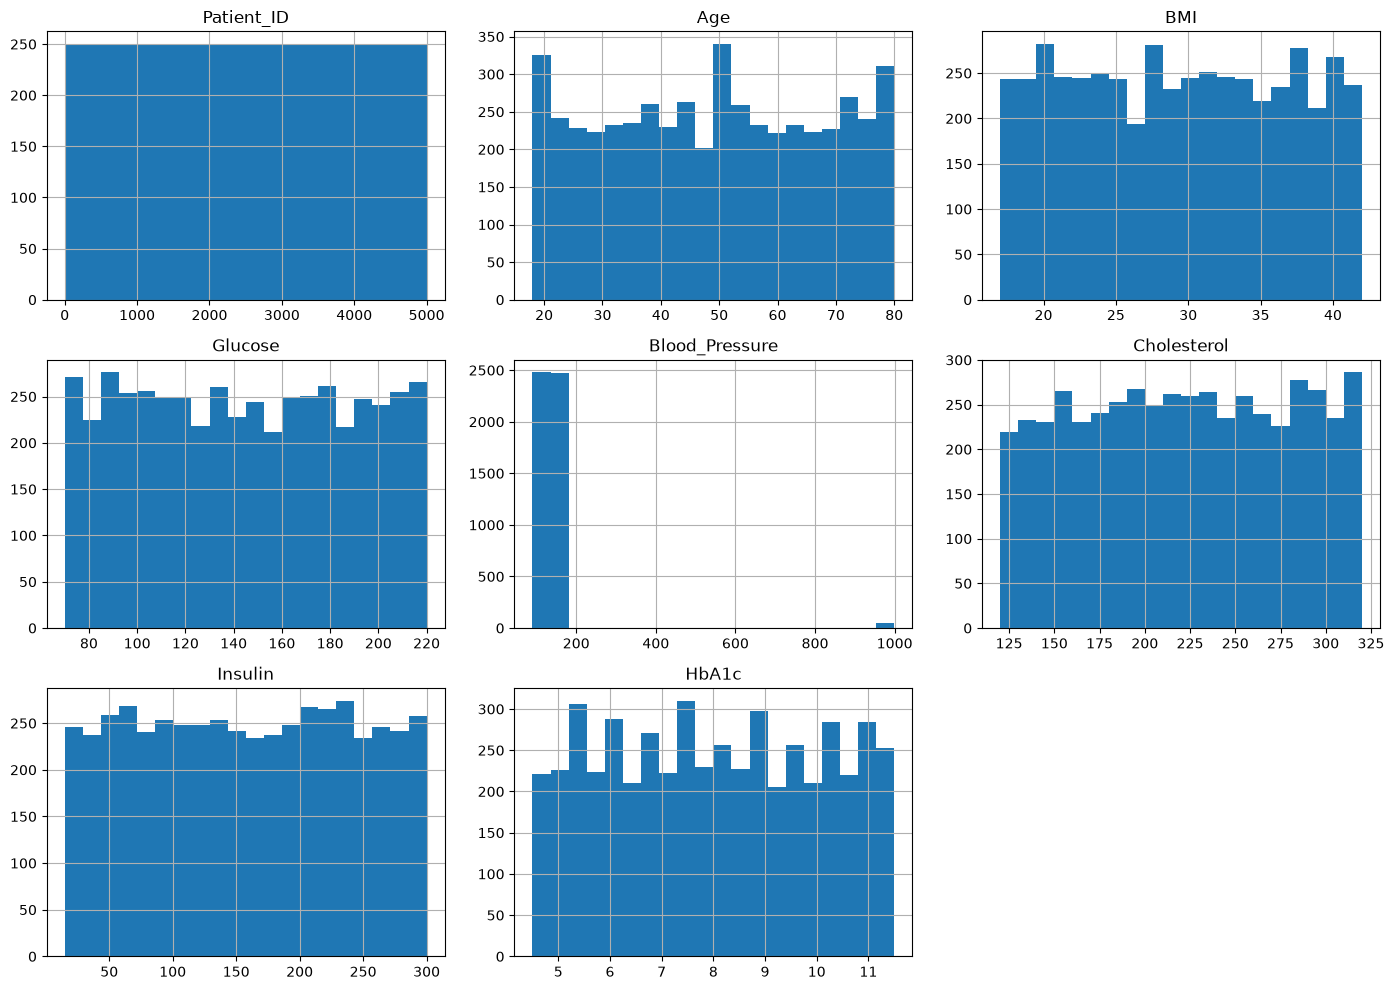

In [42]:
df[num_cols].hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

## GENDER DISTRIBUTION

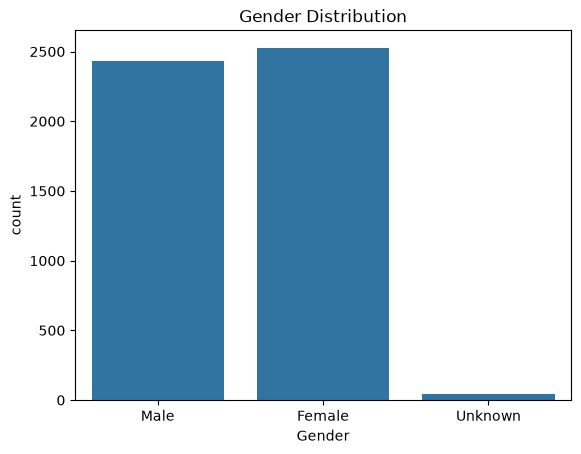

In [21]:
sns.countplot(x='Gender', data=df)
plt.title('Gender Distribution')
plt.show()

## SMOKING STATUS

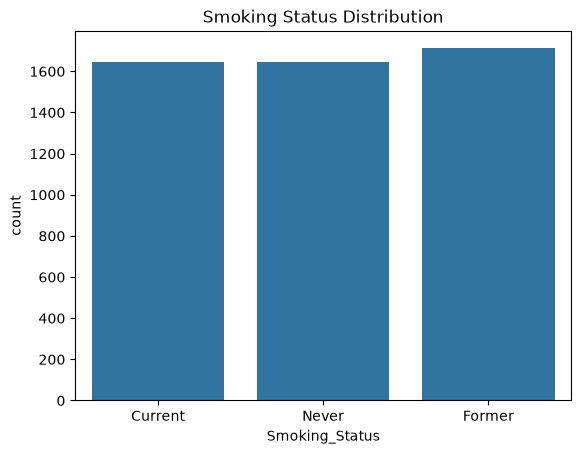

In [23]:
sns.countplot(x='Smoking_Status', data=df)
plt.title('Smoking Status Distribution')
plt.show()

## PHYSICAL ACTIVITY

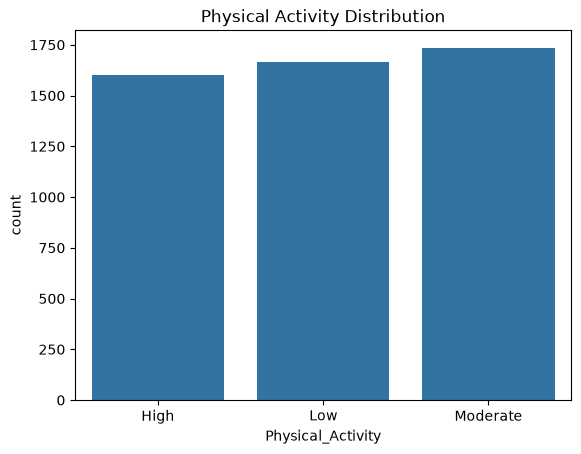

In [25]:
sns.countplot(x='Physical_Activity', data=df)
plt.title('Physical Activity Distribution')
plt.show()

## REMOVE DUPLICATE RECORDS

In [27]:
df.drop_duplicates(inplace=True)

In [28]:
df.shape

(5000, 13)

## CHECK MISSING VALUE

In [30]:
df.isnull().sum()

Patient_ID             0
Age                    0
Gender                 0
BMI                  107
Glucose               70
Blood_Pressure         0
Cholesterol            0
Insulin                0
HbA1c                  0
Smoking_Status         0
Physical_Activity      0
Family_History         0
Diabetes               0
dtype: int64

## BMI MISSING VALUE

In [32]:
df['BMI'].fillna(df['BMI'].median(), inplace=True)

0       17.6
1       31.0
2       19.4
3       34.6
4       34.5
        ... 
4995    38.0
4996    39.3
4997    41.3
4998    23.5
4999    40.6
Name: BMI, Length: 5000, dtype: float64

## GLUCOSE MISSING VALUE

In [34]:
df['Glucose'].fillna(df['Glucose'].median(), inplace=True)

0       140.0
1       209.0
2       158.0
3        81.0
4        88.0
        ...  
4995    115.0
4996    164.0
4997    174.0
4998     73.0
4999    183.0
Name: Glucose, Length: 5000, dtype: float64

In [35]:
df.isnull().sum()

Patient_ID             0
Age                    0
Gender                 0
BMI                  107
Glucose               70
Blood_Pressure         0
Cholesterol            0
Insulin                0
HbA1c                  0
Smoking_Status         0
Physical_Activity      0
Family_History         0
Diabetes               0
dtype: int64

In [43]:
X = df.drop(columns=["Diabetes", "Patient_ID"])
y = df["Diabetes"].map({"No": 0, "Yes": 1})

In [44]:


num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns

print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))

Numerical Columns: ['Age', 'BMI', 'Glucose', 'Blood_Pressure', 'Cholesterol', 'Insulin', 'HbA1c']
Categorical Columns: ['Gender', 'Smoking_Status', 'Physical_Activity', 'Family_History']


## TRAIN-TEST SPLIT

In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4000, 11)
Testing Data: (1000, 11)


In [46]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [48]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print("\nModel:", name)
    print("Accuracy:", accuracy)
    print(classification_report(y_test, y_pred))


Model: Logistic Regression
Accuracy: 0.867
              precision    recall  f1-score   support

           0       0.84      0.83      0.83       402
           1       0.88      0.89      0.89       598

    accuracy                           0.87      1000
   macro avg       0.86      0.86      0.86      1000
weighted avg       0.87      0.87      0.87      1000


Model: Decision Tree
Accuracy: 0.987
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       402
           1       0.99      0.98      0.99       598

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000


Model: Random Forest
Accuracy: 0.993
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       402
           1       0.99      0.99      0.99       598

    accuracy                           0.99      1000
   macro

## MODEL ACCURACY

In [49]:
import pandas as pd

results_df = pd.DataFrame({
    "Model": results.keys(),
    "Accuracy": results.values()
})

results_df = results_df.sort_values(by="Accuracy", ascending=False)

results_df

,Model,Accuracy
3,Gradient Boosting,0.994
2,Random Forest,0.993
1,Decision Tree,0.987
0,Logistic Regression,0.867


### VISUALISE MODEL ACCURACY

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

plt.xticks(rotation=45)
plt.show()

## SELECT BEST MODEL

In [53]:
best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)
print("Best Accuracy:", results_df.iloc[0]["Accuracy"])

Best Model: Gradient Boosting
Best Accuracy: 0.994


## SAVE TRAINED MODEL

In [56]:
import pickle

with open("diabetes_model.pkl", "wb") as file:
    pickle.dump(best_pipeline, file)

print("Model saved successfully!")

Model saved successfully!


## VERIFY SAVED MODEL

In [58]:

with open("diabetes_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!
